In [43]:
import os
import sys
from scipy.io import loadmat
from scipy.signal import butter, lfilter, sosfilt, sosfreqz
from scipy.fft import fft, ifft
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


Load the experimental data

In [44]:
data_set_exp = pd.read_csv(r"C:\Users\Utban\OneDrive - HKUST Connect\PhD\Research\Experiments with TOm\Nr_TR_22-Jan-2024\to_Utban (1)\data_filtered.csv")
data_set_exp = np.array(data_set_exp)

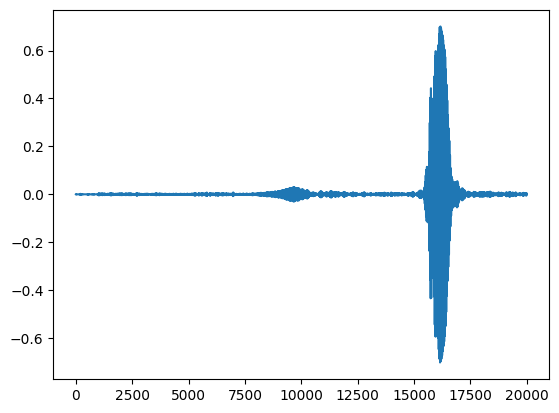

In [45]:
plt.plot(data_set_exp[:,1])

In [47]:
wavelength = 4
xx = np.arange(-100,102,2)/wavelength
max_pressure = []

for i in range(101):
    max_pressure_i = np.max(data_set_exp[:,i])
    max_pressure.append(max_pressure_i)

max_pressure = np.array(max_pressure)

Text(0, 0.5, 'max$(|P|)$')

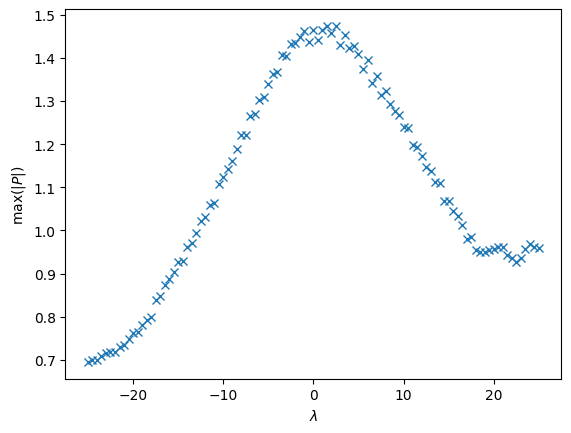

In [52]:
plt.plot(xx,max_pressure, linestyle= "None", marker = "x")
# plt.xlim(-10,10)
plt.xlabel("$\lambda$")
plt.ylabel("max$(|P|)$")


FFT

In [4]:
data_set_exp.shape[-1]

101

In [5]:
data_set_exp_fft = []

for i in range(data_set_exp.shape[-1]):
    data_fft = fft(data_set_exp[:,i])
    data_set_exp_fft.append(data_fft)

# data_set_exp_fft = np.array(data_set_exp_fft).reshape(-1,1)

Filtering the data

In [22]:
def butter_bandpass(lowcut, highcut, fs, order=5):
        nyq = 0.5 * fs
        low = lowcut / nyq
        high = highcut / nyq
        sos = butter(order, [low, high], analog=False, btype='band', output='sos')
        return sos

def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
        sos = butter_bandpass(lowcut, highcut, fs, order=order)
        y = sosfilt(sos, data)
        return y

In [32]:
f_central = 35000
band_width = 0.6
f_max = round(f_central*(1 + 0.5*band_width))
f_min = round(f_central*(1-0.5*band_width))
f_sample = round(1e6)
order = 6

filter = butter_bandpass(f_min, f_max, f_sample, order)

dat_filtered_A = butter_bandpass_filter(data_set_exp[:, 1], f_min, f_max, order)

ValueError: Digital filter critical frequencies must be 0 < Wn < 1